# 02 — Skip-prediction model

**Question:** how well can I predict whether I will skip a track, and does a model beat simple baselines?

**Label** (`y`, from `src/features.py`): 1 = skipped with the forward button (`fwdbtn`), 0 = played to the end (`trackdone`); the other outcomes are censored (notebook 01).
**Rows:** labeled, not resumes, started as in a playlist, i.e. after a finished or a skipped track (`model_rows` in `src/train.py`).
**Validation:** temporal only, train on the past and test on the future: one split at 2025-07-01, then a backtest over 7 cuts. Besides the overall metrics, the main one for choosing tracks is the AUC among *known tracks after a non-skipped track*, the case the playlist optimizes.

All numbers use the final features (rates with exponential decay, last sections).

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.append("../src")
from features import ALPHA, H_ARTIST, H_TRACK, ROOT, past_rate
from train import BOOL_COLS, DEVICES, FEATURES, model_rows, to_Z, train

df = pd.read_parquet(ROOT / "data" / "features.parquet")
data = model_rows(df)

# Temporal split: train on the past, evaluate on the future
CUT = pd.Timestamp("2025-07-01", tz="UTC")
tr = data[data["ts"] < CUT]
te = data[data["ts"] >= CUT]
print(f"train: {len(tr)} rows, rate {tr['y'].mean():.3f}")
print(f"test:  {len(te)} rows, rate {te['y'].mean():.3f}")

train: 55268 rows, rate 0.338
test:  19560 rows, rate 0.209


## Baselines

In [2]:
def evaluate(name, p):
    """Three metrics on the test set: AUC (ranking), log-loss and Brier (probabilities)."""
    auc, ll, brier = roc_auc_score(te["y"], p), log_loss(te["y"], p), brier_score_loss(te["y"], p)
    print(f"{name:<24} AUC {auc:.3f}   log-loss {ll:.4f}   Brier {brier:.4f}")


# 1. Constant: the mean rate of the training set, the same for every row
evaluate("constant", np.full(len(te), tr["y"].mean()))

# 2. Recent level: global rate of the last 30 days
evaluate("global 30 days", te["global_rate_30d"].clip(0.01, 0.99))

# 3. History of the track (shrunk towards the artist)
evaluate("track rate", te["track_rate"].clip(0.01, 0.99))

# 4. Only the skip of the previous track (rates estimated on the training set)
rates = tr.groupby(tr["prev_y"].fillna(-1))["y"].mean()
evaluate("previous skip only", te["prev_y"].fillna(-1).map(rates))

constant                 AUC 0.500   log-loss 0.5527   Brier 0.1818
global 30 days           AUC 0.603   log-loss 0.5016   Brier 0.1620
track rate               AUC 0.712   log-loss 0.4639   Brier 0.1488
previous skip only       AUC 0.751   log-loss 0.4204   Brier 0.1298


## Gradient boosting and logistic regression

In [3]:
def to_X(d):
    """Feature matrix for gradient boosting: booleans as 0/1, device as a category, NaN kept."""
    X = d[FEATURES].copy()
    X["device"] = pd.Categorical(X["device"], categories=DEVICES)
    for c in BOOL_COLS:
        X[c] = X[c].astype(int)
    return X


# Gradient boosting (trees): handles NaN, categories and interactions by itself
gb = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0)
gb.fit(to_X(tr), tr["y"])
p_gb = gb.predict_proba(to_X(te))[:, 1]
evaluate("gradient boosting", p_gb)

# Logistic regression (src/train.py): standardized features, hour as sine and cosine,
# one dummy per device, indicator for an unknown previous track
lr = train(tr)
p_lr = lr.predict_proba(to_Z(te))[:, 1]
evaluate("logistic", p_lr)

gradient boosting        AUC 0.833   log-loss 0.3778   Brier 0.1171
logistic                 AUC 0.836   log-loss 0.3775   Brier 0.1174


In [4]:
# At equal previous skip, which score ranks the tracks best?
for v, label in [(0.0, "previous NOT skipped"), (1.0, "previous skipped")]:
    s = (te["prev_y"] == v).to_numpy()
    y = te["y"][s]
    auc = [roc_auc_score(y, p[s]) for p in [te["track_rate"].to_numpy(), p_gb, p_lr]]
    scores = f"track rate {auc[0]:.3f}   GB {auc[1]:.3f}   logistic {auc[2]:.3f}"
    print(f"{label} (n = {s.sum()}):  {scores}")

previous NOT skipped (n = 15079):  track rate 0.713   GB 0.713   logistic 0.726
previous skipped (n = 4119):  track rate 0.651   GB 0.654   logistic 0.643


## Calibration

actual rate in the test set: 0.209
mean prediction, logistic:   0.203
mean prediction, GB:         0.210


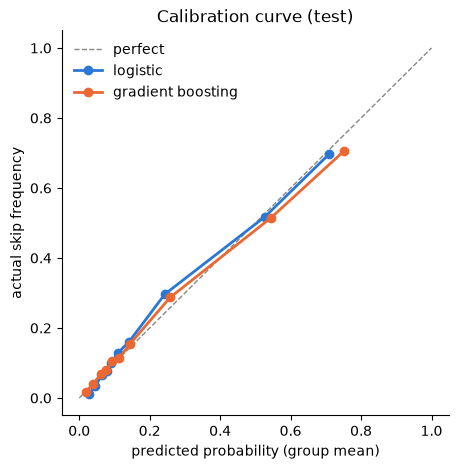

In [5]:
print(f"actual rate in the test set: {te['y'].mean():.3f}")
print(f"mean prediction, logistic:   {p_lr.mean():.3f}")
print(f"mean prediction, GB:         {p_gb.mean():.3f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color="#898781", lw=1, linestyle="--", label="perfect")
for name, p, color in [("logistic", p_lr, "#2a78d6"), ("gradient boosting", p_gb, "#eb6834")]:
    # strategy="quantile": 10 groups with the same number of rows (equal-width bins
    # would stay almost empty above 0.5)
    frac, mean_pred = calibration_curve(te["y"], p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", color=color, lw=2, label=name)
ax.set_xlabel("predicted probability (group mean)")
ax.set_ylabel("actual skip frequency")
ax.set_title("Calibration curve (test)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig(ROOT / "results" / "calibration.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Month by month: actual rate, mean predictions and recent global level
t = te.assign(p_lr=p_lr, p_gb=p_gb, month=te["ts"].dt.strftime("%Y-%m"))
t.groupby("month").agg(
    n=("y", "size"), actual=("y", "mean"), logistic=("p_lr", "mean"), GB=("p_gb", "mean"),
    global_30d=("global_rate_30d", "mean"),
).round(3)

,n,actual,logistic,GB,global_30d
month,,,,,
2025-07,680,0.251,0.228,0.240,0.218
2025-08,868,0.363,0.314,0.318,0.338
2025-09,1090,0.230,0.236,0.248,0.311
2025-10,855,0.146,0.166,0.175,0.185
2025-11,779,0.262,0.232,0.245,0.199
2025-12,828,0.391,0.326,0.342,0.339
2026-01,1078,0.159,0.176,0.172,0.252
2026-02,787,0.413,0.347,0.355,0.251
2026-03,1603,0.240,0.240,0.243,0.302


## Cold start

Groups: known track (not a first play); new track of a known artist; new artist. Split by previous skip.

In [7]:
# np.select takes the first true condition, row by row
group = np.select(
    [~te["first_play"], te["artist_n_prev"] > 0],
    ["known track", "new track, known artist"], default="new artist",
)
t = te.assign(p_lr=p_lr, p_gb=p_gb, group=group)

rows = []
for (g, v), d in t.groupby(["group", "prev_y"]):
    rows.append({
        "group": g, "prev_y": v, "n": len(d), "rate": d["y"].mean(),
        "AUC track rate": roc_auc_score(d["y"], d["track_rate"]),
        "AUC logistic": roc_auc_score(d["y"], d["p_lr"]),
        "AUC GB": roc_auc_score(d["y"], d["p_gb"]),
        "pred. logistic": d["p_lr"].mean(),  # calibration within the group
        "pred. GB": d["p_gb"].mean(),
    })
pd.DataFrame(rows).round(3)

,group,prev_y,n,rate,AUC track rate,AUC logistic,AUC GB,pred. logistic,pred. GB
0,known track,0.0,11694,0.118,0.707,0.712,0.700,0.100,0.104
1,known track,1.0,3684,0.584,0.658,0.645,0.651,0.602,0.620
2,new artist,0.0,985,0.032,0.769,0.798,0.766,0.058,0.055
3,new artist,1.0,79,0.797,0.583,0.705,0.720,0.582,0.707
4,"new track, known artist",0.0,2400,0.062,0.660,0.711,0.686,0.078,0.073
5,"new track, known artist",1.0,356,0.652,0.605,0.609,0.625,0.616,0.648


## Backtest

Rolling origin: 7 half-yearly cuts from 2023-01 to 2026-01, training on all the past, test on the following 6 months (the last one about 10 months).

In [8]:
CUTS = pd.date_range("2023-01-01", "2026-01-01", freq="6MS", tz="UTC")  # "6MS": every 6 months
WINDOW = pd.DateOffset(months=6)


def fit_predict_track(tr, te):
    """Baseline: past skip rate of the track, no training."""
    return te["track_rate"].clip(0.01, 0.99).to_numpy()


def fit_predict_lr(tr, te):
    """Logistic regression of src/train.py."""
    return train(tr).predict_proba(to_Z(te))[:, 1]


def fit_predict_gb(tr, te, **params):
    """Gradient boosting, default parameters unless given."""
    m = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0, **params)
    m.fit(to_X(tr), tr["y"])
    return m.predict_proba(to_X(te))[:, 1]


MODELS = {"track rate": fit_predict_track, "logistic": fit_predict_lr, "GB": fit_predict_gb}


def backtest(models, data, cuts=CUTS, window=WINDOW):
    """Metrics of every model on every cut (train before the cut, test on the next window)."""
    rows = []
    for cut in cuts:
        tr = data[data["ts"] < cut]
        te = data[(data["ts"] >= cut) & (data["ts"] < cut + window)]
        main = (~te["first_play"] & (te["prev_y"] == 0)).to_numpy()  # known, prev. not skipped
        for name, fit_predict in models.items():
            p = fit_predict(tr, te)
            rows.append({
                "cut": cut.date(), "model": name, "n_test": len(te), "test_rate": te["y"].mean(),
                "AUC": roc_auc_score(te["y"], p), "log-loss": log_loss(te["y"], p),
                "AUC known, prev. 0": roc_auc_score(te["y"][main], p[main]),
            })
    return pd.DataFrame(rows)


res = backtest(MODELS, data)
res.round(3)

,cut,model,n_test,test_rate,AUC,log-loss,"AUC known, prev. 0"
0,2023-01-01,track rate,3318,0.301,0.684,0.564,0.678
1,2023-01-01,logistic,3318,0.301,0.852,0.424,0.701
2,2023-01-01,GB,3318,0.301,0.837,0.435,0.648
3,2023-07-01,track rate,4490,0.169,0.762,0.391,0.727
4,2023-07-01,logistic,4490,0.169,0.894,0.278,0.769
5,2023-07-01,GB,4490,0.169,0.882,0.279,0.708
6,2024-01-01,track rate,4775,0.157,0.693,0.400,0.661
7,2024-01-01,logistic,4775,0.157,0.840,0.314,0.688
8,2024-01-01,GB,4775,0.157,0.835,0.319,0.667
9,2024-07-01,track rate,5566,0.282,0.680,0.556,0.667


In [9]:
res.groupby("model")[["AUC", "log-loss", "AUC known, prev. 0"]].agg(["mean", "std"]).round(3)

AUC        log-loss        AUC known, prev. 0       
             mean    std     mean    std               mean    std
model                                                             
GB          0.848  0.018    0.373  0.059              0.691  0.028
logistic    0.852  0.020    0.373  0.059              0.714  0.033
track rate  0.707  0.028    0.483  0.074              0.698  0.029

## Exponential decay in the rates

Past rates of artist and track with weights $2^{-\Delta t/h}$ (`past_rate` in `src/features.py`), recomputed from scratch for every half-life: the grids do not depend on the saved features.

In [10]:
def with_decay(h_artist, h_track, alpha=ALPHA):
    """Copy of df with artist and track rates recomputed; returns the model rows."""
    d = df.copy()
    d["artist_rate"] = past_rate(d, "artist", d["global_rate_30d"], alpha, h_artist)["rate"]
    d["track_rate"] = past_rate(d, "track_uri", d["artist_rate"], alpha, h_track)["rate"]
    return model_rows(d)


# Check: with the final half-lives the saved features come back
assert np.allclose(with_decay(H_ARTIST, H_TRACK)["track_rate"], data["track_rate"])

# Half-lives in days (np.inf = no decay); values = mean AUC in the main group, logistic
H = [90, 180, 365, 730, np.inf]
M = {"track rate": fit_predict_track, "logistic": fit_predict_lr}
out = []
for ha in H:
    for ht in H:
        r = backtest(M, with_decay(ha, ht))
        r["h_artist"], r["h_track"] = ha, ht
        out.append(r)
grid = pd.concat(out)
grid[grid["model"] == "logistic"].pivot_table(
    index="h_artist", columns="h_track", values="AUC known, prev. 0").round(4)

h_track,90.0,180.0,365.0,730.0,inf
h_artist,,,,,
90.0,0.7055,0.7101,0.7144,0.7151,0.7126
180.0,0.7068,0.7104,0.7135,0.7133,0.7099
365.0,0.7054,0.7087,0.7109,0.7100,0.7062
730.0,0.7035,0.7067,0.7087,0.7077,0.7036
inf,0.7004,0.7043,0.7062,0.7050,0.7008


In [11]:
# The best artist half-life is on the edge of the grid (90): shorter values
out = []
for ha in [20, 30, 45, 60, 90, np.inf]:
    r = backtest({"logistic": fit_predict_lr}, with_decay(ha, H_TRACK))
    r["h_artist"] = ha
    out.append(r)
ext = pd.concat(out)
print(ext.groupby("h_artist")[["AUC", "log-loss", "AUC known, prev. 0"]].mean().round(4), "\n")

# Difference from h_artist = inf, cut by cut (main group)
by_cut = ext.pivot(index="cut", columns="h_artist", values="AUC known, prev. 0")
by_cut.sub(by_cut[np.inf], axis=0).round(4)

             AUC  log-loss  AUC known, prev. 0
h_artist                                      
20.0      0.8545    0.3700              0.7142
30.0      0.8539    0.3706              0.7139
45.0      0.8532    0.3714              0.7141
60.0      0.8528    0.3721              0.7144
90.0      0.8522    0.3732              0.7144
inf       0.8479    0.3773              0.7062 



h_artist,20.0,30.0,45.0,60.0,90.0,inf
cut,,,,,,
2023-01-01,-0.0215,-0.0178,-0.0138,-0.0103,-0.0069,0.0
2023-07-01,0.0139,0.0127,0.0116,0.0107,0.0098,0.0
2024-01-01,0.0318,0.0278,0.0241,0.0222,0.0206,0.0
2024-07-01,0.0098,0.0061,0.0049,0.0051,0.0057,0.0
2025-01-01,0.0071,0.0092,0.0114,0.0115,0.0104,0.0
2025-07-01,0.0018,0.0022,0.0037,0.0050,0.0064,0.0
2026-01-01,0.0131,0.0137,0.0137,0.0133,0.0119,0.0


In [12]:
# Shrinkage strength alpha (artist and track), final half-lives
out = []
for a in [1, 2, 5, 10, 20, 50]:
    r = backtest({"logistic": fit_predict_lr}, with_decay(H_ARTIST, H_TRACK, alpha=a))
    r["alpha"] = a
    out.append(r)
pd.concat(out).groupby("alpha")[["AUC", "log-loss", "AUC known, prev. 0"]].mean().round(4)

,AUC,log-loss,"AUC known, prev. 0"
alpha,,,
1,0.8518,0.3731,0.7138
2,0.8522,0.3727,0.7147
5,0.8522,0.3732,0.7144
10,0.8515,0.3742,0.7121
20,0.8501,0.3759,0.7077
50,0.8473,0.3787,0.6989


## Variants not adopted

Three possible improvements, each compared with the logistic regression on the same 7 cuts: recent rows weighted more in training, gradient boosting with regularization, play counts on a log scale.

In [13]:
def fit_predict_lr_weighted(H):
    """Logistic regression with training rows weighted by age: 2^(-age/H), age in days."""
    def fit_predict(tr, te):
        age = (tr["ts"].max() - tr["ts"]).dt.total_seconds() / 86400
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        m.fit(to_Z(tr), tr["y"], logisticregression__sample_weight=2.0 ** (-age.to_numpy() / H))
        return m.predict_proba(to_Z(te))[:, 1]
    return fit_predict


def fit_predict_lr_log(tr, te):
    """Logistic regression with the play counts on a log scale."""
    def Z(d):
        z = to_Z(d)
        for c in ["track_n_prev", "artist_n_prev"]:
            z[c] = np.log1p(z[c])
        return z
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Z(tr), tr["y"])
    return m.predict_proba(Z(te))[:, 1]


def fit_predict_gb_reg(tr, te):
    """Gradient boosting with shallow trees, slower learning and L2 regularization."""
    params = dict(max_depth=3, learning_rate=0.05, max_iter=300, l2_regularization=1.0)
    return fit_predict_gb(tr, te, **params)


variants = {
    "logistic": fit_predict_lr, "weights H=180": fit_predict_lr_weighted(180),
    "weights H=365": fit_predict_lr_weighted(365), "weights H=730": fit_predict_lr_weighted(730),
    "log counts": fit_predict_lr_log, "GB regularized": fit_predict_gb_reg,
}
res_v = backtest(variants, data)

# Mean over the cuts, and difference from the logistic regression in the main group
summary = res_v.groupby("model")[["AUC", "log-loss", "AUC known, prev. 0"]].mean()
by_cut = res_v.pivot(index="cut", columns="model", values="AUC known, prev. 0")
diff = by_cut.sub(by_cut["logistic"], axis=0)
summary["diff vs logistic"] = diff.mean()
summary["cuts better"] = (diff > 0).sum()
summary.loc[list(variants)].round(4)

,AUC,log-loss,"AUC known, prev. 0",diff vs logistic,cuts better
model,,,,,
logistic,0.8522,0.3732,0.7144,0.0000,0
weights H=180,0.8538,0.3705,0.7177,0.0032,5
weights H=365,0.8539,0.3708,0.7180,0.0035,6
weights H=730,0.8535,0.3716,0.7172,0.0027,7
log counts,0.8514,0.3735,0.7155,0.0010,4
GB regularized,0.8519,0.3703,0.7060,-0.0085,3


## Conclusions

- **Baselines** (test from 2025-07, AUC / log-loss): constant 0.500 / 0.5527; recent global level 0.603 / 0.5016; track rate 0.712 / 0.4639; previous skip only 0.751 / 0.4204.
- **Models:** logistic regression 0.836 / 0.3775, gradient boosting with default parameters 0.833 / 0.3778. Most of the overall gain comes from combining the previous skip, the recent level and the track rate. **At equal previous skip** the picture is different: after a non-skipped track (n = 15,079) the logistic regression reaches 0.726 against 0.713 for the track rate alone; after a skip all scores stay at 0.64–0.65. The overall AUC alone would be misleading: the README must also report the AUC by previous skip.
- **Calibration.** Mean prediction 0.203 (logistic) and 0.210 (GB) against 0.209 actual, although the training rate is 0.338: the drift passes mostly through the features (covariate shift: lower recent level, fewer previous skips, lower track rates). No recalibration needed. Month by month the model follows the level better than `global_rate_30d` itself (February 2026: 0.347 predicted, 0.251 recent level, 0.413 actual), thanks to `prev_y`, but it damps the extreme months: errors up to 6–7 points, correlated in time (October 2026: 0.099 predicted, 0.047 actual). A playlist built in advance does not know `prev_y`, so the level is less precise there; for the power of the A/B test use the observed recent rate, not the predicted one.
- **Cold start** (after a non-skipped track):
  - known track (n = 11,694): logistic 0.712 against 0.707 for the track rate: the model barely beats the history;
  - new track of a known artist (n = 2,400): 0.711 against 0.660: the context helps where the history is weak;
  - new artist (n = 985, 32 skips): here `track_rate` equals `global_rate_30d`, so the AUC measures the period, not the track. For a new artist the model only knows the moment;
  - new tracks are overestimated (3.2% actual against 5.8% predicted for new artists; 6.2% against 7.8% for new tracks of known artists): a first play is often intentional. In the MILP new tracks are slightly penalized (a prudent error).
- **Backtest** (7 cuts, main group): logistic 0.714, track rate 0.698, GB 0.691. The logistic regression beats the track rate in 7/7 cuts (+0.016 on average, but at most +0.010 since 2024-07); GB loses to the logistic regression in 6/7. Equal log-loss (0.373). **Main model: logistic regression.**
- **Decay in the rates.** Without decay 0.701; track half-life with a plateau at 365–730 days; artist half-life with a plateau at 20–90 days (0.714), where the log-loss still improves going down (the artist rate turns into a recent level). Choice: h_artist = 90, h_track = 365 (center of the plateaus, contained worst case), 0.701 → 0.714, positive in 6/7 cuts (the only negative one is 2023-01, with little history: −0.007). Reading: the taste for a single track is stable, the relationship with an artist goes in phases. Caution: choice and measure on the same backtest, so +0.013 is slightly optimistic.
- **Shrinkage α:** plateau between 1 and 5 (0.714–0.715); larger values shrink too much (0.712 at 10, 0.699 at 50). α = 5 stays.
- **Variants not adopted:** weighting recent training rows gives +0.003 (6/7 cuts at H = 365), log-scale counts +0.001, regularized GB −0.009 (better log-loss, 0.370, but worse ranking). None changes the decisions: at the top of the ranking many tracks are tied by much more than 0.003 (notebook 03).
- **Overall:** the gain comes from the quality of the track history, not from the complexity of the model. With these data the model is close to the limit of how well tracks can be told apart.